# Predicting flight arrival delays with logistic regression
**Data:** US domestic flights, Jan–Jun 2026 (BTS on-time data joined with hourly weather at origin/destination and FAA aircraft registry).

**Target:** `ARR_DEL15` — the flight arrived 15+ minutes late (1) or not (0).

Two models are built:
* **Pre-departure model** — uses only what is known ahead of time: the schedule, the weather (forecast) at both airports, and the aircraft.
* **Same-day model** — adds how the aircraft got here: its previous flight's delay, the turnaround time, and whether the airline swapped aircraft — all known shortly before departure.

Sections: 1) load · 2) EDA · 3) cleaning & features · 4) split · 5) models · 6) evaluation · 7) interpretation · 8) robustness check

In [1]:
import os, gc, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score, accuracy_score)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
SEED = 42
RESULTS = {}          # every number quoted in the slides is collected here and saved to results.json
OUT_DIR = os.environ.get("OUT_DIR", "outputs")
os.makedirs(OUT_DIR, exist_ok=True)


# chart style: one consistent, colour-blind-checked palette
BLUE, ORANGE, AQUA, GRAY = "#257de0", "#f47230", "#00b894", "#a3a3a3"
INK, INK2, GRID, AXIS = "#191919", "#666666", "#e7e7e7", "#c2c2c2"
MODEL_COLORS = {"Schedule only": GRAY, "Pre-departure": BLUE, "Same-day": ORANGE}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "text.color": INK, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
                     "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "legend.frameon": False})
pct = lambda ax, axis="y": (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name)); plt.show()

## 1. Load the data
Only the columns needed are loaded. If the Parquet copy sits next to the CSV it is used (loads in seconds); otherwise the CSV is read.

In [2]:
DATA_DIR = os.environ.get("DATA_DIR", ".")
PARQUET = os.path.join(DATA_DIR, "flights_data_forecast.parquet")
CSV = os.path.join(DATA_DIR, "flights_data_forecast.csv")

WX = ["precipitation", "snowfall", "temperature_2m", "wind_speed_10m", "wind_gusts_10m",
      "cloud_cover", "weather_code", "pressure_msl"]
COLS = (["FL_DATE", "MONTH", "DAY_OF_WEEK", "OP_UNIQUE_CARRIER", "TAIL_NUM", "ORIGIN", "DEST",
         "CRS_DEP_TIME", "CRS_ARR_TIME", "DEP_TIME_BLK", "arr_datetime",
         "DEP_DEL15", "ARR_DEL15", "ARR_DELAY", "CANCELLED", "CANCELLATION_CODE", "DIVERTED",
         "CRS_ELAPSED_TIME", "DISTANCE",
         "CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY",
         "MAKER", "SEATS", "PLANE_AGE"]
        + [f"origin_{w}" for w in WX] + [f"dest_{w}" for w in WX])

t0 = time.time()
if os.path.exists(PARQUET):
    df = pd.read_parquet(PARQUET, columns=COLS)
else:
    df = pd.read_csv(CSV, usecols=COLS, low_memory=False)
for c in ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DEP_TIME_BLK", "CANCELLATION_CODE"]:
    df[c] = df[c].astype("category")
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"])
df["arr_datetime"] = pd.to_datetime(df["arr_datetime"])
print(f"Loaded {len(df):,} rows x {df.shape[1]} cols in {time.time()-t0:.0f}s")
RESULTS["n_rows"] = int(len(df)); RESULTS["n_cols_file"] = 71
RESULTS["date_min"] = str(df.FL_DATE.min().date()); RESULTS["date_max"] = str(df.FL_DATE.max().date())
RESULTS["n_days"] = int(df.FL_DATE.nunique()); RESULTS["n_carriers"] = int(df.OP_UNIQUE_CARRIER.nunique())
RESULTS["n_airports"] = int(pd.concat([df.ORIGIN.astype(str), df.DEST.astype(str)]).nunique())

Loaded 3,488,373 rows x 43 cols in 5s


## 2. Exploratory data analysis
### 2a. Target and what is missing
Cancelled and diverted flights never arrive normally, so `ARR_DEL15` is blank for them. They are excluded from the delay model (cancellation is a separate problem).

In [3]:
EDA_COLS = ["MONTH", "DAY_OF_WEEK", "DEP_TIME_BLK", "OP_UNIQUE_CARRIER", "ORIGIN", "DEP_DEL15", "ARR_DEL15",
            "origin_weather_code", "dest_weather_code", "origin_snowfall", "dest_snowfall",
            "origin_precipitation", "dest_precipitation", "origin_wind_gusts_10m", "dest_wind_gusts_10m"]
flown = df.loc[(df.CANCELLED == 0) & (df.DIVERTED == 0), EDA_COLS]
RESULTS["n_cancelled"] = int((df.CANCELLED == 1).sum()); RESULTS["n_diverted"] = int((df.DIVERTED == 1).sum())
RESULTS["cancel_rate"] = float(df.CANCELLED.mean())
RESULTS["arr_del15_rate"] = float(flown.ARR_DEL15.mean())
RESULTS["n_flown"] = int(len(flown))
print(f"Cancelled: {RESULTS['n_cancelled']:,} ({RESULTS['cancel_rate']:.1%})   Diverted: {RESULTS['n_diverted']:,}")
print(f"Flights that arrived: {len(flown):,};  share delayed 15+ min: {RESULTS['arr_del15_rate']:.1%}")
print("\nCancellation codes (A=carrier, B=weather, C=NAS, D=security):")
print(df.CANCELLATION_CODE.value_counts())

Cancelled: 76,082 (2.2%)   Diverted: 9,670
Flights that arrived: 3,402,621;  share delayed 15+ min: 22.1%

Cancellation codes (A=carrier, B=weather, C=NAS, D=security):
CANCELLATION_CODE
B    55355
A    14262
C     6391
D       74
Name: count, dtype: int64


### 2b. Leakage check
Many columns are *outcomes* — they are only known after the flight. Using them would give a near-perfect but useless model.
For example, departure delay alone predicts arrival delay almost perfectly:

In [4]:
p_given_dep = flown.groupby("DEP_DEL15").ARR_DEL15.mean()
RESULTS["p_arr_given_dep_late"] = float(p_given_dep.loc[1.0]); RESULTS["p_arr_given_dep_ontime"] = float(p_given_dep.loc[0.0])
RESULTS["corr_dep_arr"] = float(flown[["DEP_DEL15", "ARR_DEL15"]].corr().iloc[0, 1])
print(p_given_dep.rename("P(arrival delayed)"))
LEAKAGE = ["DEP_DELAY", "DEP_DELAY_NEW", "DEP_DEL15", "DEP_DELAY_GROUP", "ARR_DELAY", "ARR_DELAY_NEW",
           "ARR_DELAY_GROUP", "CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY",
           "LATE_AIRCRAFT_DELAY", "CANCELLED", "CANCELLATION_CODE", "DIVERTED"]
RESULTS["n_leakage_cols"] = len(LEAKAGE)
print(f"\n{len(LEAKAGE)} outcome columns are excluded from the features:", ", ".join(LEAKAGE))

DEP_DEL15
0.0    0.057303
1.0    0.785601
Name: P(arrival delayed), dtype: float64

15 outcome columns are excluded from the features: DEP_DELAY, DEP_DELAY_NEW, DEP_DEL15, DEP_DELAY_GROUP, ARR_DELAY, ARR_DELAY_NEW, ARR_DELAY_GROUP, CARRIER_DELAY, WEATHER_DELAY, NAS_DELAY, SECURITY_DELAY, LATE_AIRCRAFT_DELAY, CANCELLED, CANCELLATION_CODE, DIVERTED


### 2c. What causes the delay minutes?
For delayed flights the data records how many minutes came from each cause.

In [5]:
cause_cols = {"Late-arriving aircraft": "LATE_AIRCRAFT_DELAY", "Carrier (crew, maintenance)": "CARRIER_DELAY",
              "Air traffic system (NAS)": "NAS_DELAY", "Weather": "WEATHER_DELAY", "Security": "SECURITY_DELAY"}
cause = pd.Series({k: df[v].sum() for k, v in cause_cols.items()})
cause_share = (cause / cause.sum()).sort_values(ascending=False)
RESULTS["cause_share"] = {k: float(v) for k, v in cause_share.items()}
print((cause_share * 100).round(1).astype(str) + " %")

Late-arriving aircraft         39.3 %
Carrier (crew, maintenance)    34.0 %
Air traffic system (NAS)       20.0 %
Weather                         6.5 %
Security                        0.2 %
dtype: str


### 2d. Delay rate by month, hour, carrier, day of week

        mean    size
MONTH               
1      0.208  517222
2      0.198  502396
3      0.243  592256
4      0.202  591206
5      0.214  604346
6      0.257  595195
               mean    size
DEP_TIME_BLK               
0001-0559     0.092  101260
0600-0659     0.100  233194
0700-0759     0.127  253363
0800-0859     0.146  233053
0900-0959     0.163  192426
1000-1059     0.181  215462
1100-1159     0.198  208235
1200-1259     0.219  206502
1300-1359     0.234  201263
1400-1459     0.257  192828
1500-1559     0.268  195764
1600-1659     0.290  196597
1700-1759     0.293  215108
1800-1859     0.309  199780
1900-1959     0.311  187562
2000-2059     0.317  151781
2100-2159     0.294  113036
2200-2259     0.274   76221
2300-2359     0.192   29186
                    mean    size
OP_UNIQUE_CARRIER               
DL                 0.178  497746
AS                 0.187  162267
MQ                 0.190  154045
UA                 0.197  404982
YX                 0.199  174437
OO           

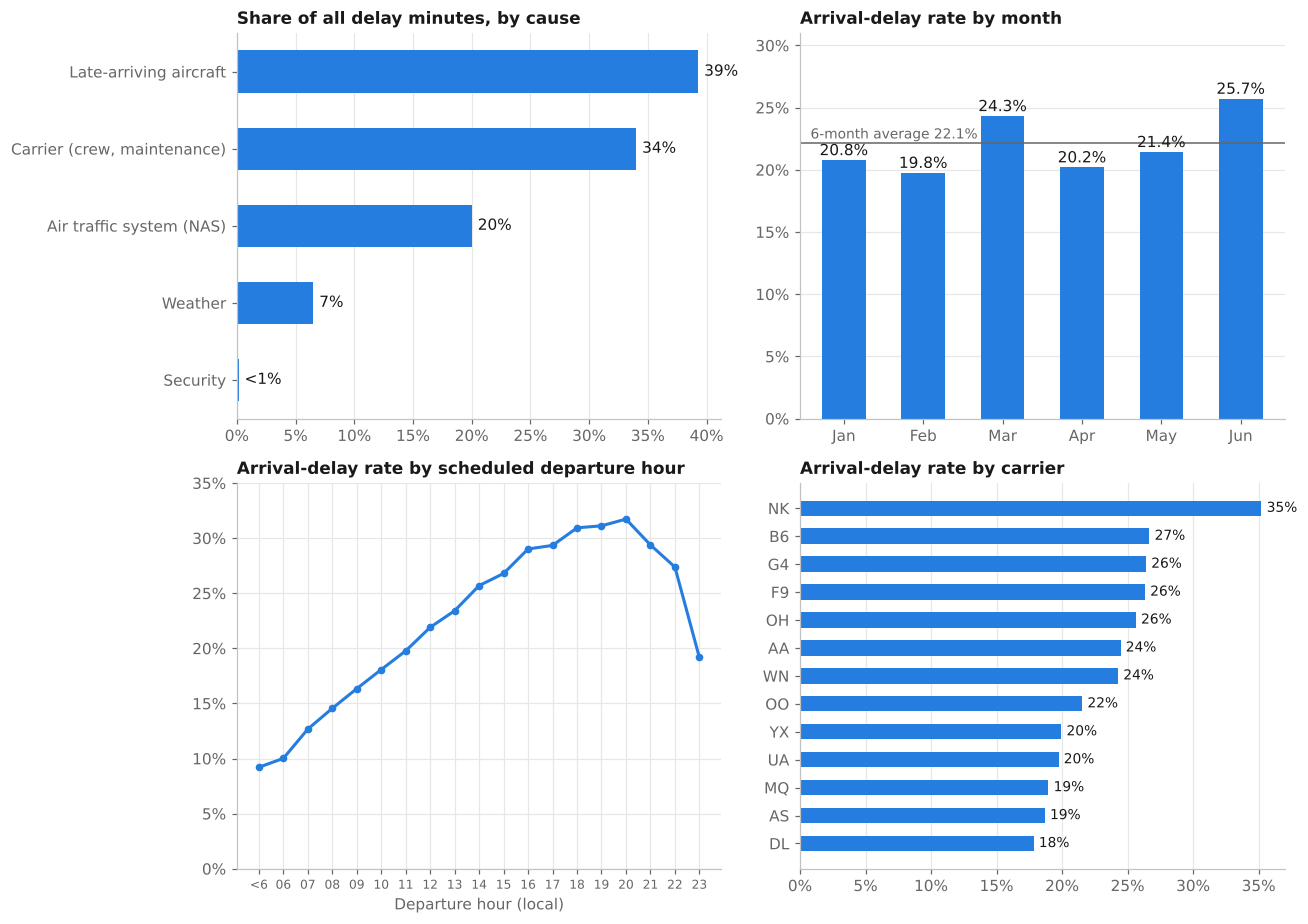

In [6]:
by_month = flown.groupby("MONTH").ARR_DEL15.agg(["mean", "size"])
by_hour = flown.groupby("DEP_TIME_BLK", observed=True).ARR_DEL15.agg(["mean", "size"])
by_carrier = flown.groupby("OP_UNIQUE_CARRIER", observed=True).ARR_DEL15.agg(["mean", "size"]).sort_values("mean")
by_dow = flown.groupby("DAY_OF_WEEK").ARR_DEL15.mean()
RESULTS["by_month"] = {int(k): float(v) for k, v in by_month["mean"].items()}
RESULTS["by_hour"] = {str(k): float(v) for k, v in by_hour["mean"].items()}
RESULTS["by_carrier"] = {str(k): float(v) for k, v in by_carrier["mean"].items()}
RESULTS["by_carrier_n"] = {str(k): int(v) for k, v in by_carrier["size"].items()}
RESULTS["by_dow"] = {int(k): float(v) for k, v in by_dow.items()}
print(by_month.round(3)); print(by_hour.round(3)); print(by_carrier.round(3)); print(by_dow.round(3))


fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
ax = axes[0, 0]
ax.barh(cause_share.index[::-1], cause_share.values[::-1], color=BLUE, height=0.55)
for i, v in enumerate(cause_share.values[::-1]): ax.text(v + 0.005, i, f"{v:.0%}" if v >= 0.01 else "<1%", va="center", color=INK)
ax.set_title("Share of all delay minutes, by cause"); pct(ax, "x"); ax.grid(axis="y", visible=False)
ax = axes[0, 1]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
ax.bar(months, by_month["mean"].values, color=BLUE, width=0.55)
for i, v in enumerate(by_month["mean"].values): ax.text(i, v + 0.004, f"{v:.1%}", ha="center", color=INK)
ax.axhline(RESULTS["arr_del15_rate"], color=INK2, lw=1); ax.text(-0.42, RESULTS["arr_del15_rate"] + 0.004, f"6-month average {RESULTS['arr_del15_rate']:.1%}", color=INK2, ha="left", fontsize=9)
ax.set_title("Arrival-delay rate by month"); pct(ax); ax.set_ylim(0, 0.31); ax.grid(axis="x", visible=False)
ax = axes[1, 0]
hrs = [b[:2] for b in by_hour.index]
ax.plot(range(len(hrs)), by_hour["mean"].values, color=BLUE, lw=2, marker="o", ms=4)
ax.set_xticks(range(len(hrs)), [("<6" if h == "00" else h) for h in hrs], fontsize=8)
ax.set_title("Arrival-delay rate by scheduled departure hour"); pct(ax); ax.set_ylim(0, 0.35); ax.set_xlabel("Departure hour (local)")
ax = axes[1, 1]
ax.barh(by_carrier.index, by_carrier["mean"].values, color=BLUE, height=0.55)
for i, v in enumerate(by_carrier["mean"].values): ax.text(v + 0.004, i, f"{v:.0%}", va="center", color=INK, fontsize=9)
ax.set_title("Arrival-delay rate by carrier"); pct(ax, "x"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "eda_1_overview.png")

### 2e. Weather
Weather codes follow the WMO standard; they are grouped into readable categories.

Delay rate by weather at ORIGIN at the scheduled departure hour:
               mean     size
o_wx                        
Clear         0.204  1141357
Cloudy        0.223  2082706
Fog           0.081       62
Drizzle       0.264    94592
Rain          0.319    38077
Snow          0.543    20890
Rain showers  0.395     7870
Snow showers  0.311      193
Thunderstorm  0.346      208
Missing       0.254    16666



Snow at either airport: {'yes': 0.4541875799626021, 'no': 0.21840185105371035, 'n_yes': 40644}
Precipitation at either airport: {'yes': 0.3055644475485584, 'no': 0.2127855395793692}
Max gust at either airport (km/h):
           rate          n
<20    0.206627  2446020.0
20–30  0.246306   818303.0
30–40  0.318701   126639.0
40–50  0.458679    10975.0
50+    0.528551      683.0


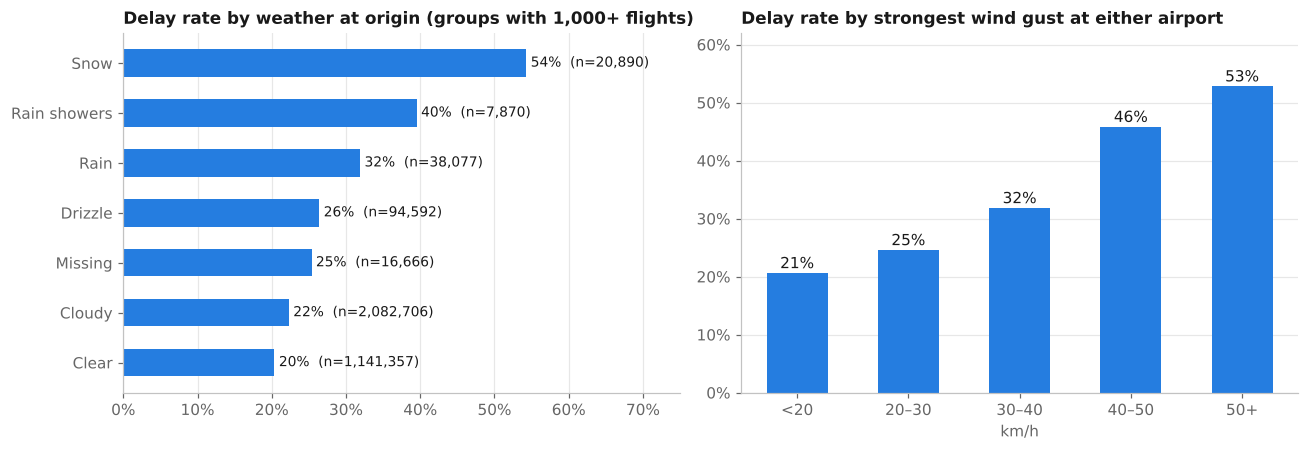

In [7]:
def wx_group(code):
    """WMO weather code -> readable group."""
    bins = pd.cut(code, bins=[-1, 0, 3, 48, 57, 67, 77, 82, 86, 99],
                  labels=["Clear", "Cloudy", "Fog", "Drizzle", "Rain", "Snow", "Rain showers", "Snow showers", "Thunderstorm"])
    return bins.cat.add_categories("Missing").fillna("Missing")

flown = flown.assign(o_wx=wx_group(flown.origin_weather_code), d_wx=wx_group(flown.dest_weather_code))
wx_tab = flown.groupby("o_wx", observed=True).ARR_DEL15.agg(["mean", "size"])
print("Delay rate by weather at ORIGIN at the scheduled departure hour:"); print(wx_tab.round(3))
# snow / any precipitation at either end
either_snow = (flown.origin_snowfall > 0) | (flown.dest_snowfall > 0)
either_prcp = (flown.origin_precipitation > 0) | (flown.dest_precipitation > 0)
gust_max = flown[["origin_wind_gusts_10m", "dest_wind_gusts_10m"]].max(axis=1)
gust_bin = pd.cut(gust_max, [-1, 20, 30, 40, 50, 200], labels=["<20", "20–30", "30–40", "40–50", "50+"])
RESULTS["wx_origin"] = {str(k): {"rate": float(r), "n": int(n)} for k, (r, n) in wx_tab.iterrows()}
RESULTS["snow_either"] = {"yes": float(flown.ARR_DEL15[either_snow].mean()), "no": float(flown.ARR_DEL15[~either_snow].mean()), "n_yes": int(either_snow.sum())}
RESULTS["prcp_either"] = {"yes": float(flown.ARR_DEL15[either_prcp].mean()), "no": float(flown.ARR_DEL15[~either_prcp].mean())}
RESULTS["gust_max_bins"] = {str(k): {"rate": float(r), "n": int(n)} for k, (r, n) in flown.groupby(gust_bin, observed=True).ARR_DEL15.agg(["mean", "size"]).iterrows()}
print("\nSnow at either airport:", RESULTS["snow_either"])
print("Precipitation at either airport:", RESULTS["prcp_either"])
print("Max gust at either airport (km/h):"); print(pd.DataFrame(RESULTS["gust_max_bins"]).T)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
w = wx_tab[wx_tab["size"] >= 1000].sort_values("mean")
ax.barh(w.index.astype(str), w["mean"].values, color=BLUE, height=0.55)
for i, (v, n) in enumerate(zip(w["mean"].values, w["size"].values)): ax.text(v + 0.006, i, f"{v:.0%}  (n={n:,})", va="center", color=INK, fontsize=9)
ax.set_title("Delay rate by weather at origin (groups with 1,000+ flights)"); pct(ax, "x"); ax.set_xlim(0, 0.75); ax.grid(axis="y", visible=False)
ax = axes[1]
gb = pd.DataFrame(RESULTS["gust_max_bins"]).T
ax.bar(gb.index, gb["rate"].values, color=BLUE, width=0.55)
for i, v in enumerate(gb["rate"].values): ax.text(i, v + 0.008, f"{v:.0%}", ha="center", color=INK)
ax.set_title("Delay rate by strongest wind gust at either airport"); ax.set_xlabel("km/h"); pct(ax); ax.set_ylim(0, 0.62); ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "eda_2_weather.png")

### 2f. Hubs

In [8]:
by_origin = flown.groupby("ORIGIN", observed=True).ARR_DEL15.agg(["mean", "size"]).sort_values("size", ascending=False)
RESULTS["top_origins"] = {str(k): {"rate": float(r), "n": int(n)} for k, (r, n) in by_origin.head(15).iterrows()}
print(by_origin.head(15).round(3))
del flown

         mean    size
ORIGIN               
ORD     0.292  174278
DEN     0.224  154310
ATL     0.212  151537
DFW     0.273  146895
PHX     0.214  101070
LAX     0.203   92021
CLT     0.229   86010
LAS     0.221   83699
MCO     0.253   80739
SEA     0.182   77607
SFO     0.238   71523
BOS     0.235   68374
DCA     0.267   67688
LGA     0.246   62951
SLC     0.151   58739


## 3. Cleaning and feature engineering
### 3a. Data quality fixes
* **Aircraft registry mismatches** — some tail numbers matched the wrong FAA record (drones, helicopters, gliders, 0-seat entries). Aircraft details are blanked for any maker that isn't an airliner manufacturer or for planes with fewer than 30 seats.
* **Maker names** — "AIRBUS", "AIRBUS INDUSTRIE", "AIRBUS SAS"… are merged into one group (same for Embraer/Yabora, Bombardier, A220/C Series).
* **Missing weather** — Palm Beach (PBI) has no weather rows; numeric weather is filled with the median and the weather group is set to "Missing".
* **Impossible schedule** — 9 rows with scheduled flight time ≤ 0 are dropped.

In [9]:
maker = df.MAKER.fillna("").str.strip().str.upper()
maker_group = np.select(
    [maker.str.startswith("BOEING"),
     maker.str.startswith("AIRBUS") | maker.str.startswith("C SERIES"),
     maker.str.contains("EMBRAER") | maker.str.startswith("YABORA") | maker.str.startswith("EMPRESA BRASILEIRA"),
     maker.str.startswith("BOMBARDIER")],
    ["Boeing", "Airbus", "Embraer", "Bombardier"], default="Unknown")
bad_ac = (maker_group == "Unknown") | (df.SEATS < 30)
RESULTS["n_bad_aircraft_rows"] = int(((maker_group == "Unknown") & (maker != "")).sum() + ((maker_group != "Unknown") & (df.SEATS < 30)).sum())
RESULTS["n_missing_aircraft_rows"] = int(bad_ac.sum())
df["maker_group"] = np.where(bad_ac, "Unknown", maker_group)
df.loc[bad_ac, ["SEATS", "PLANE_AGE"]] = np.nan
df["age_missing"] = df.PLANE_AGE.isna().astype(np.int8)
print("Maker groups:"); print(df.maker_group.value_counts())
print(f"Rows with aircraft details blanked or missing: {bad_ac.sum():,}")
RESULTS["n_wx_missing"] = int(df.origin_temperature_2m.isna().sum())

Maker groups:
maker_group
Boeing        1611333
Airbus         962343
Embraer        560751
Bombardier     322578
Unknown         31368
Name: count, dtype: int64
Rows with aircraft details blanked or missing: 31,368


### 3b. Aircraft rotation features (same-day model only)
Each aircraft (tail number) flies a chain of flights. Ordering each aircraft's flights by scheduled departure gives its **previous leg**.

**Leakage trap found during EDA:** `TAIL_NUM` is the aircraft that *actually* flew, not the one planned in advance. When an airline swaps aircraft on the day,
the rotation "breaks" — the previous leg ends at a different airport, or is scheduled to land *after* this flight should depart. Those breaks are
strong delay signals (see table below) but only knowable on the day. So **every rotation feature — turnaround time, leg of day, breaks, previous-leg delay —
is used only in the same-day model**, never in the pre-departure model.

Delay rate by how this flight's aircraft arrived:
                            mean    size
rotation                                
Turn 3–8 h                 0.131  308662
First flight of day        0.144  520705
Turn 90–180 min            0.186  238697
Turn 60–90 min             0.199  782128
Turn 45–60 min             0.230  728992
Turn <45 min               0.278  650812
Gap > 8 h                  0.321   38330
Prev. leg ended elsewhere  0.421   95282
Overlap (swap)             0.918   39013


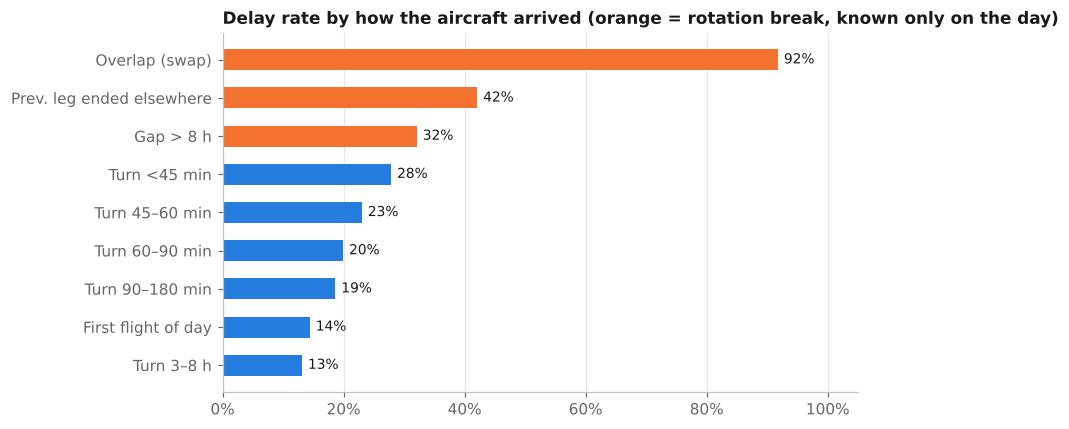

In [10]:
dep_min = (df.CRS_DEP_TIME // 100) * 60 + df.CRS_DEP_TIME % 100
arr_hhmm = df.CRS_ARR_TIME.where(df.CRS_ARR_TIME != 2400, 0)
df["dep_ts"] = df.FL_DATE + pd.to_timedelta(dep_min, unit="m")
df["arr_ts"] = df.arr_datetime.dt.normalize() + pd.to_timedelta((arr_hhmm // 100) * 60 + arr_hhmm % 100, unit="m")

df = df.sort_values(["TAIL_NUM", "dep_ts"], kind="mergesort").reset_index(drop=True); gc.collect()
g = df.groupby("TAIL_NUM", sort=False, observed=True)
prev_dest = g.DEST.shift().astype(object)
prev_date = g.FL_DATE.shift()
prev_arr_ts = g.arr_ts.shift()
prev_arr_delay = g.ARR_DELAY.shift()
prev_arr_del15 = g.ARR_DEL15.shift()
prev_disrupted = (g.CANCELLED.shift() == 1) | (g.DIVERTED.shift() == 1)
turn = (df.dep_ts - prev_arr_ts).dt.total_seconds() / 60

has_tail = df.TAIL_NUM.notna()
same_airport = prev_dest.eq(df.ORIGIN.astype(object))
connected = has_tail & same_airport & (turn <= 480)           # previous leg feeds this flight (incl. overnight)
turn_cat = pd.cut(turn, [-np.inf, 0, 45, 60, 90, 180, 481], right=False,
                  labels=["Overlap (swap)", "Turn <45 min", "Turn 45–60 min", "Turn 60–90 min", "Turn 90–180 min", "Turn 3–8 h"]).astype(str)
df["rotation"] = np.select(
    [~has_tail, prev_dest.isna(), connected, ~same_airport, prev_date.eq(df.FL_DATE)],
    ["No tail number", "First flight of day", turn_cat, "Prev. leg ended elsewhere", "Gap > 8 h"],
    default="First flight of day")
df["leg_of_day"] = (df.groupby(["TAIL_NUM", "FL_DATE"], observed=True).cumcount() + 1).clip(upper=6)
df.loc[~has_tail, "leg_of_day"] = 1

known_prev = connected & ~prev_disrupted & prev_arr_delay.notna()
df["prev_late"] = (known_prev & (prev_arr_del15 == 1)).astype(np.int8)
excess = (prev_arr_delay - (turn - 35)).clip(lower=0, upper=300)   # ~35 min is a typical minimum turn
df["log_inbound_excess"] = np.log1p(excess.where(known_prev, 0))
df["prev_disrupted"] = (connected & prev_disrupted).astype(np.int8)

rot_tab = df[(df.CANCELLED == 0) & (df.DIVERTED == 0)].groupby("rotation").ARR_DEL15.agg(["mean", "size"]).sort_values("mean")
RESULTS["rotation_rates"] = {k: {"rate": float(r), "n": int(n)} for k, (r, n) in rot_tab.iterrows()}
RESULTS["share_connected"] = float(connected.mean())
print("Delay rate by how this flight's aircraft arrived:"); print(rot_tab.round(3))
del g, prev_dest, prev_date, prev_arr_ts, prev_arr_delay, prev_arr_del15, prev_disrupted, turn, turn_cat, excess, known_prev, connected, same_airport
gc.collect()


fig, ax = plt.subplots(figsize=(8, 4))
colors = [ORANGE if k in ("Overlap (swap)", "Prev. leg ended elsewhere", "Gap > 8 h") else BLUE for k in rot_tab.index]
ax.barh(rot_tab.index, rot_tab["mean"].values, color=colors, height=0.55)
for i, v in enumerate(rot_tab["mean"].values): ax.text(v + 0.01, i, f"{v:.0%}", va="center", color=INK, fontsize=9)
ax.set_title("Delay rate by how the aircraft arrived (orange = rotation break, known only on the day)"); pct(ax, "x"); ax.set_xlim(0, 1.05); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "rotation_breaks.png")

### 3c. Schedule features
* **Congestion** — scheduled departures from the origin in the same hour, and scheduled arrivals at the destination in the same hour (log).
* **Schedule buffer** — scheduled flight time minus the median scheduled time for that route. Airlines pad some schedules, which absorbs delay.
* **Holiday window** — within 2 days of a federal holiday or Easter.

In [11]:
dep_hour = df.CRS_DEP_TIME // 100
arr_hour = arr_hhmm // 100
df["log_origin_cong"] = np.log1p(df.groupby([df.ORIGIN, df.FL_DATE, dep_hour], observed=True).CRS_DEP_TIME.transform("size"))
df["log_dest_cong"] = np.log1p(df.groupby([df.DEST, df.arr_ts.dt.normalize(), arr_hour], observed=True).CRS_ARR_TIME.transform("size"))
route_med = df.groupby(["ORIGIN", "DEST"], observed=True).CRS_ELAPSED_TIME.transform("median")
df["sched_buffer"] = (df.CRS_ELAPSED_TIME - route_med).clip(-30, 45)
df["log_distance"] = np.log(df.DISTANCE)
holidays = pd.to_datetime(["2026-01-01", "2026-01-19", "2026-02-16", "2026-04-05", "2026-05-25", "2026-06-19"])
days_to_hol = np.min(np.abs(df.FL_DATE.values[:, None] - holidays.values[None, :]).astype("timedelta64[D]").astype(int), axis=1)
df["near_holiday"] = (days_to_hol <= 2).astype(np.int8)

# top-30 airports kept as categories, the rest pooled as OTHER
TOP_N = 30
top_o = df.ORIGIN.value_counts().head(TOP_N).index
top_d = df.DEST.value_counts().head(TOP_N).index
df["origin_grp"] = np.where(df.ORIGIN.isin(top_o), df.ORIGIN.astype(str), "OTHER")
df["dest_grp"] = np.where(df.DEST.isin(top_d), df.DEST.astype(str), "OTHER")

### 3d. Weather features (origin and destination)
Grouped weather type, precipitation (log), snow yes/no, wind-gust band, temperature band, cloud cover, sea-level pressure.

In [12]:
for side, p in [("origin", "o"), ("dest", "d")]:
    df[f"{p}_wx"] = wx_group(df[f"{side}_weather_code"]).astype(str)
    df[f"{p}_log_prcp"] = np.log1p(df[f"{side}_precipitation"])
    df[f"{p}_snow"] = (df[f"{side}_snowfall"] > 0).astype(np.int8)
    df[f"{p}_gust"] = pd.cut(df[f"{side}_wind_gusts_10m"], [-1, 20, 30, 40, 50, 500],
                             labels=["<20", "20–30", "30–40", "40–50", "50+"]).astype(str).replace("nan", "Missing")
    df[f"{p}_temp"] = pd.cut(df[f"{side}_temperature_2m"], [-100, -10, 0, 10, 20, 30, 100],
                             labels=["<-10C", "-10–0C", "0–10C", "10–20C", "20–30C", "30C+"]).astype(str).replace("nan", "Missing")
    df[f"{p}_cloud"] = df[f"{side}_cloud_cover"] / 100
    df[f"{p}_pressure"] = df[f"{side}_pressure_msl"]

df["DEP_TIME_BLK"] = df.DEP_TIME_BLK.astype(str)
df["carrier"] = df.OP_UNIQUE_CARRIER.astype(str)
df["dow"] = df.DAY_OF_WEEK.astype(str)
df["month"] = df.MONTH.astype(str)

### 3e. Modeling table
Keep flights that actually flew (not cancelled/diverted) with a valid schedule.

In [13]:
# feature sets ----------------------------------------------------------------
CAT_SCHED = ["carrier", "DEP_TIME_BLK", "dow", "month", "origin_grp", "dest_grp"]
NUM_SCHED = ["log_distance", "sched_buffer", "log_origin_cong", "log_dest_cong"]
BIN_SCHED = ["near_holiday"]
CAT_WX = ["o_wx", "d_wx", "o_gust", "d_gust", "o_temp", "d_temp", "maker_group"]
NUM_WX = ["o_log_prcp", "d_log_prcp", "o_cloud", "d_cloud", "o_pressure", "d_pressure", "PLANE_AGE", "SEATS"]
BIN_WX = ["o_snow", "d_snow", "age_missing"]
CAT_SAME = ["rotation"]
NUM_SAME = ["leg_of_day", "log_inbound_excess"]
BIN_SAME = ["prev_late", "prev_disrupted"]

# reference (baseline) category for each categorical, so odds ratios read "vs. this"
REF = {"carrier": "WN", "DEP_TIME_BLK": "0600-0659", "dow": "2", "month": "1", "origin_grp": "OTHER",
       "dest_grp": "OTHER", "rotation": "First flight of day", "o_wx": "Clear", "d_wx": "Clear", "o_gust": "<20",
       "d_gust": "<20", "o_temp": "10–20C", "d_temp": "10–20C", "maker_group": "Boeing"}

FEATURE_SETS = {
    "Schedule only": (CAT_SCHED, NUM_SCHED, BIN_SCHED),
    "Pre-departure": (CAT_SCHED + CAT_WX, NUM_SCHED + NUM_WX, BIN_SCHED + BIN_WX),
    "Same-day": (CAT_SCHED + CAT_WX + CAT_SAME, NUM_SCHED + NUM_WX + NUM_SAME, BIN_SCHED + BIN_WX + BIN_SAME),
}

keep = list(dict.fromkeys(["FL_DATE", "MONTH", "ARR_DEL15"] + sum([a + b + c for a, b, c in FEATURE_SETS.values()], [])))
model_df = df.loc[(df.CANCELLED == 0) & (df.DIVERTED == 0) & (df.CRS_ELAPSED_TIME > 0), keep].reset_index(drop=True)
del df; gc.collect()
model_df["y"] = model_df.pop("ARR_DEL15").astype(np.int8)
RESULTS["n_model_rows"] = int(len(model_df))
print(f"Modeling rows: {len(model_df):,}   delayed share: {model_df.y.mean():.3f}")

# fill numeric gaps (weather at PBI, aircraft age/seats) with the median
for c in NUM_SCHED + NUM_WX + NUM_SAME:
    model_df[c] = model_df[c].astype(np.float32).fillna(np.float32(model_df[c].median()))
for c in BIN_SCHED + BIN_WX + BIN_SAME:
    model_df[c] = model_df[c].astype(np.float32)
for c in CAT_SCHED + CAT_WX + CAT_SAME:
    model_df[c] = model_df[c].astype(str).astype("category")
gc.collect()
print(model_df.shape, f"{model_df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Modeling rows: 3,402,619   delayed share: 0.221


(3402619, 37) 0.38 GB


## 4. Train / validation / test split
Flights on the same day share weather and congestion, so a random row split would leak information between sets.
Instead **whole days** are assigned: within each month, 70% of days go to training, 15% to validation (tuning) and 15% to the final test.

In [14]:
rng = np.random.default_rng(SEED)
days = pd.Series(sorted(model_df.FL_DATE.unique()))
split_of_day = {}
for m, d in days.groupby(days.dt.month):
    d = d.sample(frac=1, random_state=SEED + m).tolist()
    n_tr, n_va = round(len(d) * 0.70), round(len(d) * 0.15)
    for i, day in enumerate(d):
        split_of_day[day] = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")
model_df["split"] = model_df.FL_DATE.map(split_of_day)
split_summary = model_df.groupby("split").agg(days=("FL_DATE", "nunique"), flights=("y", "size"), delay_rate=("y", "mean"))
RESULTS["split"] = {k: {"days": int(r.days), "flights": int(r.flights), "delay_rate": float(r.delay_rate)} for k, r in split_summary.iterrows()}
print(split_summary)
tr, va, te = (model_df[model_df.split == s] for s in ["train", "val", "test"])
y_tr, y_va, y_te = tr.y.values, va.y.values, te.y.values

       days  flights  delay_rate
split                           
test     26   498313    0.214407
train   128  2394789    0.219752
val      27   509517    0.234771


## 5. Models
Each model is a scikit-learn pipeline: one-hot encoding (with a fixed reference category) for categorical columns, standardisation for continuous columns, binary flags passed through, then L2-regularised logistic regression.

### 5a. Tune regularisation strength `C` on the validation set (pre-departure feature set)

In [15]:
def make_pipe(cats, nums, bins, C=1.0, class_weight=None):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(drop=[REF[c] for c in cats], handle_unknown="ignore", sparse_output=True, dtype=np.float32), cats),
        ("num", StandardScaler(), nums),
        ("bin", "passthrough", bins)], sparse_threshold=1.0)
    clf = LogisticRegression(C=C, solver="lbfgs", max_iter=2000, class_weight=class_weight)
    return Pipeline([("prep", pre), ("clf", clf)])

def scores(y, p):
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "log_loss": log_loss(y, p), "brier": brier_score_loss(y, p)}

cats, nums, bins = FEATURE_SETS["Pre-departure"]
tuning = []
for C in [0.001, 0.01, 0.1, 1.0]:
    t0 = time.time()
    pipe = make_pipe(cats, nums, bins, C=C).fit(tr, y_tr)
    s = scores(y_va, pipe.predict_proba(va)[:, 1]); s["C"] = C; s["secs"] = round(time.time() - t0)
    tuning.append(s); print(s)
tuning = pd.DataFrame(tuning)
BEST_C = float(tuning.loc[tuning.log_loss.idxmin(), "C"])
RESULTS["tuning"] = tuning.to_dict(orient="records"); RESULTS["best_C"] = BEST_C
print("Best C by validation log loss:", BEST_C)

{'roc_auc': 0.683419031167165, 'pr_auc': 0.4061971729773225, 'log_loss': 0.5058523416519165, 'brier': 0.1650691032409668, 'C': 0.001, 'secs': 30}


{'roc_auc': 0.6870957525770517, 'pr_auc': 0.4095280276129931, 'log_loss': 0.50423663854599, 'brier': 0.16447819769382477, 'C': 0.01, 'secs': 33}


{'roc_auc': 0.6874573488214988, 'pr_auc': 0.4099277413320158, 'log_loss': 0.5041249990463257, 'brier': 0.1644265353679657, 'C': 0.1, 'secs': 33}


{'roc_auc': 0.6875273709263812, 'pr_auc': 0.4099699056898792, 'log_loss': 0.5040885806083679, 'brier': 0.16441668570041656, 'C': 1.0, 'secs': 33}
Best C by validation log loss: 1.0


### 5b. Fit the three models (and a class-weighted variant for comparison)

In [16]:
models, val_pred, test_pred = {}, {}, {}
for name, (cats, nums, bins) in FEATURE_SETS.items():
    t0 = time.time()
    models[name] = make_pipe(cats, nums, bins, C=BEST_C).fit(tr, y_tr)
    val_pred[name] = models[name].predict_proba(va)[:, 1]
    test_pred[name] = models[name].predict_proba(te)[:, 1]
    print(f"{name:15s} fitted in {time.time()-t0:.0f}s, iterations={models[name].named_steps['clf'].n_iter_[0]}, "
          f"features={models[name].named_steps['prep'].transform(va.head(1)).shape[1]}")

cats, nums, bins = FEATURE_SETS["Pre-departure"]
balanced = make_pipe(cats, nums, bins, C=BEST_C, class_weight="balanced").fit(tr, y_tr)
p_bal = balanced.predict_proba(te)[:, 1]
RESULTS["balanced_vs_plain"] = {"balanced": scores(y_te, p_bal), "plain": scores(y_te, test_pred["Pre-departure"]),
                                "balanced_mean_pred": float(p_bal.mean()), "plain_mean_pred": float(test_pred["Pre-departure"].mean())}
print(pd.DataFrame(RESULTS["balanced_vs_plain"]).T.iloc[:2])

Schedule only   fitted in 14s, iterations=50, features=106


Pre-departure   fitted in 35s, iterations=66, features=161


Same-day        fitted in 42s, iterations=68, features=173


           roc_auc    pr_auc  log_loss     brier
balanced  0.685755  0.380224  0.659025  0.233384
plain     0.684774  0.380590  0.483410  0.155594


## 6. Evaluation on the held-out test days
Accuracy is misleading here — always predicting "on time" is right 78% of the time — so the main metrics are ROC-AUC and PR-AUC (ranking quality), log loss and Brier score (probability quality).
A decision threshold is chosen on the validation set to maximise F1, then applied unchanged to the test set.

In [17]:
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    i = np.nanargmax(f1[:-1]); return float(thr[i])

rows = [{"model": "Always 'on time'", "roc_auc": 0.5, "pr_auc": float(y_te.mean()),
         "log_loss": log_loss(y_te, np.full(len(y_te), y_tr.mean())), "brier": brier_score_loss(y_te, np.full(len(y_te), y_tr.mean())),
         "threshold": None, "accuracy": accuracy_score(y_te, np.zeros_like(y_te)), "precision": 0.0, "recall": 0.0, "f1": 0.0}]
for name in FEATURE_SETS:
    thr = best_f1_threshold(y_va, val_pred[name]); p = test_pred[name]; yhat = (p >= thr).astype(int)
    r = {"model": name, **scores(y_te, p), "threshold": thr, "accuracy": accuracy_score(y_te, yhat),
         "precision": precision_score(y_te, yhat), "recall": recall_score(y_te, yhat), "f1": f1_score(y_te, yhat)}
    r["cm"] = confusion_matrix(y_te, yhat).tolist()
    r["acc_at_0.5"] = accuracy_score(y_te, (p >= 0.5).astype(int)); r["recall_at_0.5"] = recall_score(y_te, (p >= 0.5).astype(int))
    r["precision_at_0.5"] = precision_score(y_te, (p >= 0.5).astype(int))
    rows.append(r)
metrics = pd.DataFrame(rows).set_index("model")
RESULTS["test_metrics"] = json.loads(metrics.to_json(orient="index"))
print(metrics.drop(columns=["cm"]).round(3).to_string())

                  roc_auc  pr_auc  log_loss  brier  threshold  accuracy  precision  recall     f1  acc_at_0.5  recall_at_0.5  precision_at_0.5
model                                                                                                                                         
Always 'on time'    0.500   0.214     0.520  0.168        NaN     0.786      0.000   0.000  0.000         NaN            NaN               NaN
Schedule only       0.662   0.343     0.493  0.159      0.223     0.582      0.294   0.678  0.410       0.786          0.026             0.520
Pre-departure       0.685   0.381     0.483  0.156      0.227     0.616      0.314   0.665  0.426       0.789          0.080             0.559
Same-day            0.815   0.682     0.370  0.111      0.305     0.840      0.646   0.560  0.600       0.858          0.459             0.789


### ROC and precision–recall curves; calibration

Actual delay rate by predicted-risk decile (pre-departure): [0.079 0.102 0.124 0.149 0.176 0.203 0.236 0.279 0.336 0.461]
Actual delay rate by predicted-risk decile (same-day):      [0.051 0.065 0.077 0.092 0.107 0.132 0.159 0.22  0.376 0.865]


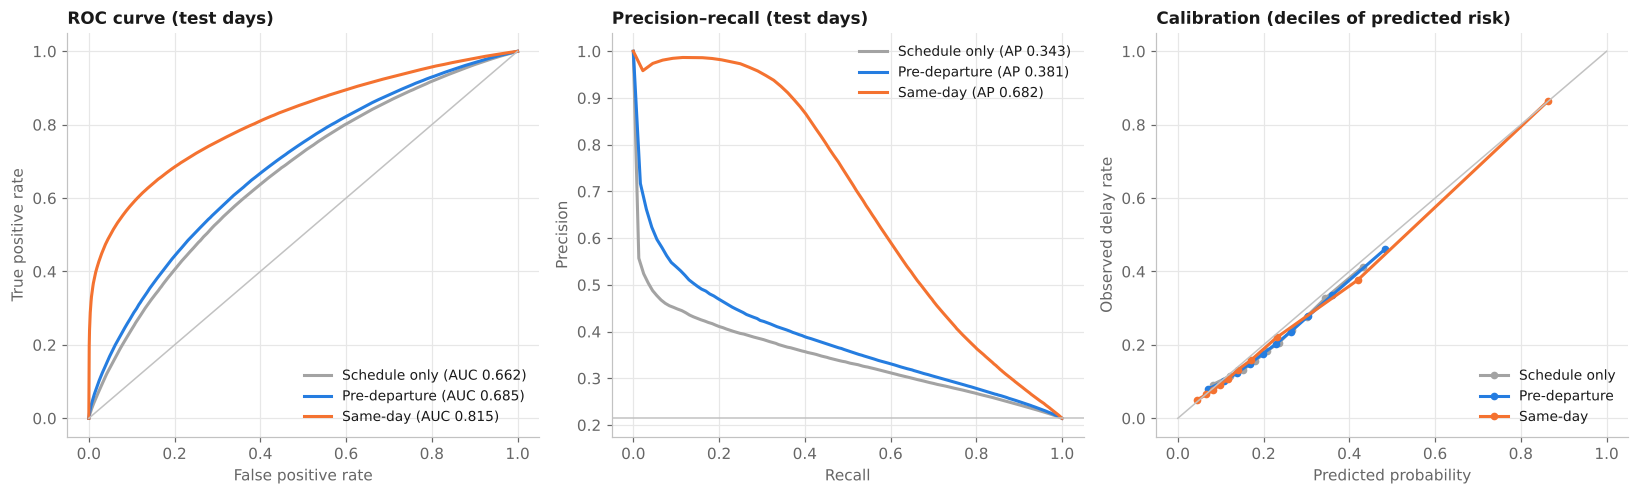

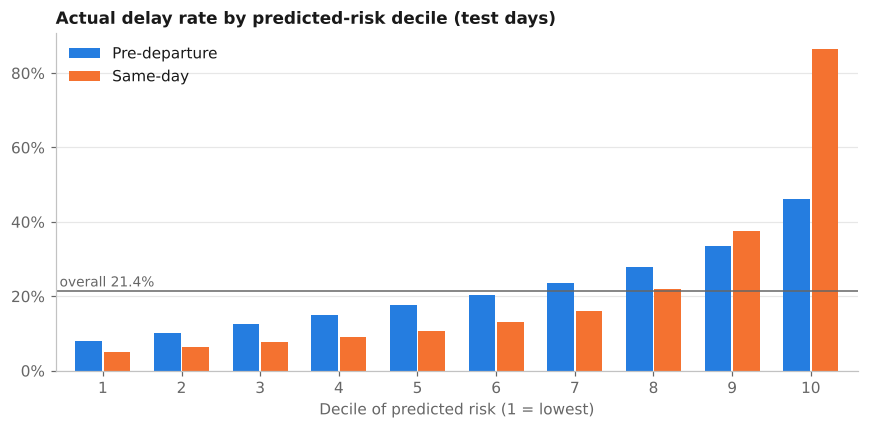

In [18]:
curves = {}
for name in FEATURE_SETS:
    fpr, tpr, _ = roc_curve(y_te, test_pred[name])
    idx = np.linspace(0, len(fpr) - 1, 200).astype(int)
    prec, rec, _ = precision_recall_curve(y_te, test_pred[name])
    jdx = np.linspace(0, len(prec) - 1, 200).astype(int)
    frac_pos, mean_pred = calibration_curve(y_te, test_pred[name], n_bins=10, strategy="quantile")
    curves[name] = {"fpr": fpr[idx].tolist(), "tpr": tpr[idx].tolist(), "precision": prec[jdx].tolist(), "recall": rec[jdx].tolist(),
                    "cal_pred": mean_pred.tolist(), "cal_obs": frac_pos.tolist()}
RESULTS["curves"] = curves

# predicted-risk deciles: how concentrated are the delays?
dec = pd.qcut(test_pred["Same-day"], 10, labels=False)
RESULTS["decile_rate_sameday"] = pd.Series(y_te).groupby(dec).mean().tolist()
dec = pd.qcut(test_pred["Pre-departure"], 10, labels=False)
RESULTS["decile_rate_predep"] = pd.Series(y_te).groupby(dec).mean().tolist()
print("Actual delay rate by predicted-risk decile (pre-departure):", np.round(RESULTS["decile_rate_predep"], 3))
print("Actual delay rate by predicted-risk decile (same-day):     ", np.round(RESULTS["decile_rate_sameday"], 3))


fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for name, c in curves.items():
    auc = RESULTS["test_metrics"][name]["roc_auc"]; ap = RESULTS["test_metrics"][name]["pr_auc"]
    axes[0].plot(c["fpr"], c["tpr"], color=MODEL_COLORS[name], lw=2, label=f"{name} (AUC {auc:.3f})")
    axes[1].plot(c["recall"], c["precision"], color=MODEL_COLORS[name], lw=2, label=f"{name} (AP {ap:.3f})")
    axes[2].plot(c["cal_pred"], c["cal_obs"], color=MODEL_COLORS[name], lw=2, marker="o", ms=4, label=name)
axes[0].plot([0, 1], [0, 1], color=AXIS, lw=1); axes[0].set(title="ROC curve (test days)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_te.mean(), color=AXIS, lw=1); axes[1].set(title="Precision–recall (test days)", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], color=AXIS, lw=1); axes[2].set(title="Calibration (deciles of predicted risk)", xlabel="Predicted probability", ylabel="Observed delay rate")
for ax in axes: ax.legend(loc="lower right" if ax is not axes[1] else "upper right", fontsize=9)
fig.tight_layout(); save(fig, "model_curves.png")


fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, 11)
ax.bar(x - 0.18, RESULTS["decile_rate_predep"], width=0.34, color=BLUE, label="Pre-departure")
ax.bar(x + 0.18, RESULTS["decile_rate_sameday"], width=0.34, color=ORANGE, label="Same-day")
ax.axhline(y_te.mean(), color=INK2, lw=1); ax.text(0.45, y_te.mean() + 0.012, f"overall {y_te.mean():.1%}", color=INK2, ha="left", fontsize=9)
ax.set_xticks(x); ax.set(title="Actual delay rate by predicted-risk decile (test days)", xlabel="Decile of predicted risk (1 = lowest)")
pct(ax); ax.legend(loc="upper left"); ax.grid(axis="x", visible=False); ax.set_xlim(0.4, 10.6)
fig.tight_layout(); save(fig, "risk_deciles.png")

## 7. Interpretation — odds ratios
`exp(coefficient)` is the multiplicative change in the odds of a delay.
* One-hot features: compared with the reference category (e.g. carrier vs. Southwest, departure hour vs. 06:00–06:59, weather vs. clear).
* Continuous features: per one standard deviation increase.
* Binary flags: when the flag is on.

Pre-departure model — largest odds ratios:
               feature  coef  odds_ratio
DEP_TIME_BLK_2300-2359 0.907       2.477
          d_gust_40–50 0.937       2.551
DEP_TIME_BLK_1100-1159 0.982       2.670
DEP_TIME_BLK_1200-1259 1.087       2.965
          o_temp_<-10C 1.132       3.100
DEP_TIME_BLK_1300-1359 1.194       3.299
DEP_TIME_BLK_1400-1459 1.301       3.672
DEP_TIME_BLK_2200-2259 1.317       3.733
DEP_TIME_BLK_1500-1559 1.347       3.845
DEP_TIME_BLK_2100-2159 1.401       4.059
DEP_TIME_BLK_1600-1659 1.461       4.310
DEP_TIME_BLK_1700-1759 1.489       4.434
DEP_TIME_BLK_2000-2059 1.507       4.515
DEP_TIME_BLK_1800-1859 1.528       4.609
DEP_TIME_BLK_1900-1959 1.541       4.669

Smallest odds ratios:
            feature   coef  odds_ratio
         carrier_UA -0.574       0.563
         carrier_DL -0.497       0.608
         carrier_AS -0.428       0.652
     origin_grp_SLC -0.338       0.713
maker_group_Embraer -0.320       0.726
       dest_grp_SLC -0.251       0.778
     

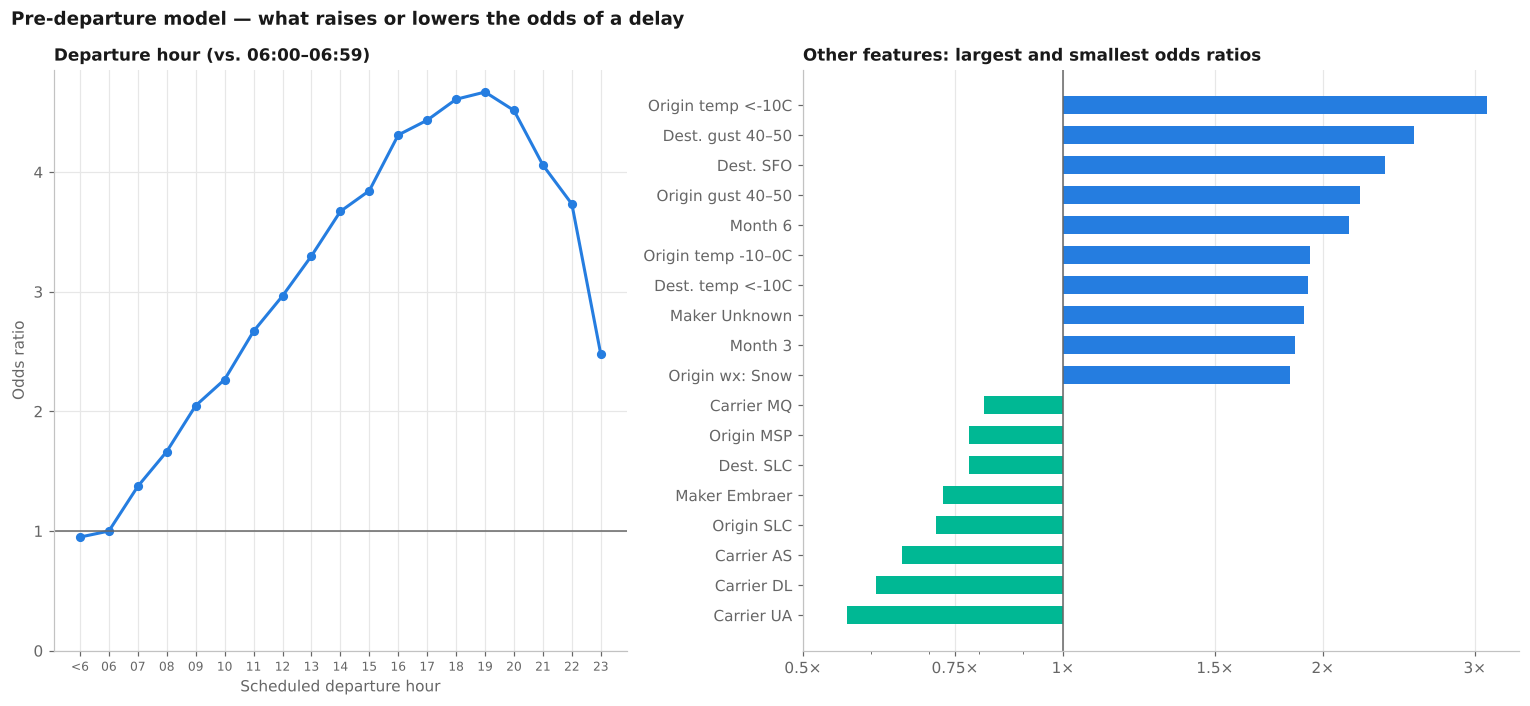

In [19]:
def odds_table(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    coef = pipe.named_steps["clf"].coef_[0]
    t = pd.DataFrame({"feature": names, "coef": coef, "odds_ratio": np.exp(coef)})
    t["feature"] = t.feature.str.replace(r"^(cat|num|bin)__", "", regex=True)
    return t.sort_values("coef")

odds_pre = odds_table(models["Pre-departure"]); odds_same = odds_table(models["Same-day"])
RESULTS["odds_predep"] = odds_pre.set_index("feature").odds_ratio.to_dict()
RESULTS["odds_sameday"] = odds_same.set_index("feature").odds_ratio.to_dict()
RESULTS["intercept_predep"] = float(models["Pre-departure"].named_steps["clf"].intercept_[0])
print("Pre-departure model — largest odds ratios:"); print(odds_pre.tail(15).round(3).to_string(index=False))
print("\nSmallest odds ratios:"); print(odds_pre.head(10).round(3).to_string(index=False))
print("\nSame-day model — previous-leg features:")
print(odds_same[odds_same.feature.str.startswith("rotation") | odds_same.feature.isin(NUM_SAME + BIN_SAME)].round(3).to_string(index=False))
odds_pre.to_csv(os.path.join(OUT_DIR, "odds_ratios_predeparture.csv"), index=False)
odds_same.to_csv(os.path.join(OUT_DIR, "odds_ratios_sameday.csv"), index=False)


def pretty(f):
    f = f.replace("DEP_TIME_BLK_", "Dep. ").replace("carrier_", "Carrier ").replace("origin_grp_", "Origin ").replace("dest_grp_", "Dest. ")
    f = f.replace("o_wx_", "Origin wx: ").replace("d_wx_", "Dest. wx: ").replace("o_gust_", "Origin gust ").replace("d_gust_", "Dest. gust ")
    f = f.replace("o_temp_", "Origin temp ").replace("d_temp_", "Dest. temp ").replace("month_", "Month ").replace("dow_", "Weekday ")
    return f.replace("maker_group_", "Maker ").replace("rotation_", "")
t = odds_pre[~odds_pre.feature.str.contains("Missing")]
hour = t[t.feature.str.startswith("DEP_TIME_BLK_")].copy()
hour["blk"] = hour.feature.str.replace("DEP_TIME_BLK_", "")
hour = pd.concat([hour, pd.DataFrame({"blk": ["0600-0659"], "odds_ratio": [1.0]})]).sort_values("blk")
rest = t[~t.feature.str.startswith("DEP_TIME_BLK_")]
show = pd.concat([rest.head(8), rest.tail(10)])
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.plot(range(len(hour)), hour.odds_ratio.values, color=BLUE, lw=2, marker="o", ms=5)
ax.set_xticks(range(len(hour)), [("<6" if b[:2] == "00" else b[:2]) for b in hour.blk], fontsize=8)
ax.axhline(1, color=INK2, lw=1); ax.set_ylim(0, None)
ax.set(title="Departure hour (vs. 06:00–06:59)", xlabel="Scheduled departure hour", ylabel="Odds ratio")
ax = axes[1]
ax.barh([pretty(f) for f in show.feature], show.odds_ratio - 1, left=1, color=[BLUE if v > 1 else AQUA for v in show.odds_ratio], height=0.6)
ax.axvline(1, color=INK2, lw=1); ax.set_xscale("log")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3]); ax.set_xticklabels(["0.5×", "0.75×", "1×", "1.5×", "2×", "3×"])
ax.set_title("Other features: largest and smallest odds ratios"); ax.grid(axis="y", visible=False)
fig.suptitle("Pre-departure model — what raises or lowers the odds of a delay", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "odds_ratios_predeparture.png")

## 8. Robustness check — predicting a future month
The main split mixes days from every month. A stricter test trains on **January–May** and predicts **June**, a month the model has never seen (month is dropped as a feature because June has no training data). June also had the highest delay rate, so this is a harder, more realistic test.

In [20]:
fwd = {}
tr_f = model_df[model_df.MONTH <= 5]; te_f = model_df[model_df.MONTH == 6]
for name in ["Pre-departure", "Same-day"]:
    cats, nums, bins = FEATURE_SETS[name]
    cats = [c for c in cats if c != "month"]
    pipe = make_pipe(cats, nums, bins, C=BEST_C).fit(tr_f, tr_f.y.values)
    p = pipe.predict_proba(te_f)[:, 1]
    fwd[name] = {**scores(te_f.y.values, p), "mean_pred": float(p.mean()), "actual_rate": float(te_f.y.mean())}
RESULTS["forward_june"] = fwd
print(pd.DataFrame(fwd).T.round(3))

               roc_auc  pr_auc  log_loss  brier  mean_pred  actual_rate
Pre-departure    0.704   0.438     0.528  0.176      0.210        0.257
Same-day         0.825   0.730     0.397  0.122      0.236        0.257


In [21]:
with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(RESULTS, f, indent=1, default=float)
print("Saved", os.path.join(OUT_DIR, "results.json"))

Saved outputs/results.json
